# Assignment 3 – 1D linear Kalman filter for the distance to a wall

**Mobile Robotics, KU Leuven** · Team: Cogilniceanu David (r0973221), Toghrul Alibayov (r0874286)

**Goal.** Estimate the distance $d$ from the robot's front edge to the wall by fusing wheel odometry (prediction, Assignment 2 scenario 1) with the calibrated front distance sensor (correction), for the position controller of the course template. Extensions (motor model, IMU) are in `Assignment3_extensions.ipynb`. Recordings: `data/A3/` (see `LOGBOOK.md`).

| | Design | Value / source |
|---|---|---|
| State | $x = -d/R_\text{wheel}$ [rad] (`Meas2State` of the template) | grows when driving forward |
| Input | $u = \omega = (\omega_A+\omega_B)/2$ [rad/s] | encoders |
| $F$, $B$ | $1$, $\Delta t$ | $\Delta t$ = 0.01 s |
| $Q(\omega)$ | $\Delta t^2\big(\sigma_\omega^2 + (k\,\omega)^2\big)$ | $\sigma_\omega$ = 0.182 rad/s (A2), $k$ = 0.05 (W1–W7) |
| $H$ | $-R_\text{wheel}$, on the calibrated distance $d = c_2m^2 + c_1m + c_0$ | $m$ = `getFrontDistance()` |
| $R(d)$ | $\big(c\,\frac{\mathrm dd}{\mathrm dm}\frac{(m-0.0109)^2}{24.7694}\big)^2 + \sigma_\text{cal}^2$ | $c$ = 0.83 counts, $\sigma_\text{cal}$ = 2 mm |
| $P_0$ | $(5\text{ mm}/R_\text{wheel})^2$ = 0.0237 rad² | tape start in ValueOut1 |
| Gate | raw $m$ < 0.40 m, calibrated $d$ in 0.04–0.32 m, $\nu^2 \le 9S$; re-sync after 20 rejections with $P$ = 9.5 rad² | |

In [1]:
import re, sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': 0.3})
pd.set_option('display.width', 200)

# Robot constants, data folders and log reader are shared (../mr_common.py)
sys.path.insert(0, '..')
from mr_common import R_WHEEL, DT, DATA_A2, DATA_A3, load_log, window, wheel_speed_noise

## 1. Prediction model

Assignment 2 scenario 1 in the state unit: $x_{k+1} = x_k + \Delta t\,\omega_k$. $\sigma_\omega = \sigma_v/R_\text{wheel}$, with $\sigma_v$ the spread of the wheel speed at constant voltage (A2 run R4).

In [2]:
R4 = load_log(DATA_A2 / 'R4_straight_fwd700mm_right190mm_turnR15deg.csv')
sig_wA, sig_wB, SIGMA_V, _ = wheel_speed_noise(R4)          # steady 6 V windows of R4, as in Assignment 2
SIGMA_OMEGA = SIGMA_V / R_WHEEL
F, B = 1.0, DT
Q = (B * SIGMA_OMEGA) ** 2                                  # A2 value: Q standing still
print(f'sigma_v = {SIGMA_V*1e3:.2f} mm/s -> sigma_omega = {SIGMA_OMEGA:.3f} rad/s, Q(0) = {Q:.2e} rad^2 per step')

sigma_v = 5.90 mm/s -> sigma_omega = 0.182 rad/s, Q(0) = 3.30e-06 rad^2 per step


## 2. Sensor calibration

`getFrontDistance()` returns $m = 24.7694/\text{raw} + 0.0109$ (library curve), which over-reads this sensor by +17 mm (5 cm) to +71 mm (30 cm). A filter cannot remove a systematic error, so every reading is calibrated before the update: $d = c_2m^2 + c_1m + c_0$, $d$ = tape distance from the robot's front edge (this also absorbs the sensor's 10 mm set-back). Fitted on 12 points, each the mean of a standstill window: the static recordings S_50 … S_300 and the start (300 mm) and end (42–45 mm) of the drives W1–W3 (the later drives W4–W7 are used for validation only). Valid 42–300 mm.

* **Quadratic:** on the S points it predicts held-out points better than the Sharp form $a/(\text{raw}+k)+b$ (leave-one-out rms 4.2 vs 5.3 mm), and costs two multiplications on the Arduino.
* **W standstill points:** at the edge of the range (30 cm) the reading depends on the set-up (≈ 4 ADC counts between S_300 and the W starts), so points recorded in the drive set-up are included; closed-loop targets stay at 100–200 mm.

In [3]:
SHARP_A, SHARP_B = 24.7694, 0.0109311               # library curve (sharp41S.cpp)
TAPE_MM = [50, 100, 150, 200, 250, 300]             # data/A3/S_<d>mm.csv

rows = []
for d in TAPE_MM:
    m = load_log(DATA_A3 / f'S_{d}mm.csv', firmware='identification_a3').front.values
    rows.append(dict(tape=d / 1e3, m=m.mean(), m_std=m.std()))
stat = pd.DataFrame(rows)

def load_w(path):
    mt = re.match(r'W(\d+)_(?:\w+_)?start(\d+)_end(\d+)', path.stem)          # W4_2V5_start300_end55: voltage in the name
    df = load_log(path, firmware='identification_a3')
    w = ((df.wA + df.wB) / 2).values
    mv = np.flatnonzero(np.abs(w) > 0)
    return dict(name=path.stem, t=df.t.values, m=df.front.values, w=w, d_start=int(mt[2]) / 1e3, d_end=int(mt[3]) / 1e3,
                drive=slice(mv[0], mv[-1] + 30))                            # wheels turning + 0.3 s

def standstill(r):
    # (start, end) windows: before the drive and from 1 s after the wheels stop
    t0 = r['t'][r['drive']][0]; t_stop = r['t'][np.flatnonzero(np.abs(r['w']) > 0)[-1]]
    return (r['t'] > 0.5) & (r['t'] < t0 - 0.2), r['t'] > t_stop + 1.0

WRUNS = [load_w(p) for p in sorted(DATA_A3.glob('W*_start*_end*.csv'))]
CAL_RUNS = ['W1', 'W2', 'W3']                                       # W runs in the calibration of the firmware
pts = [dict(source='S', tape=r.tape, m=r.m) for r in stat.itertuples()]
for r in [r for r in WRUNS if r['name'][:2] in CAL_RUNS]:
    sel_start, sel_end = standstill(r)
    pts.append(dict(source=r['name'][:2] + ' start', tape=r['d_start'], m=r['m'][sel_start].mean()))
    pts.append(dict(source=r['name'][:2] + ' end', tape=r['d_end'], m=r['m'][sel_end].mean()))
cal_pts = pd.DataFrame(pts)

def fit_cal(points):
    return tuple(np.polyfit(points.m, points.tape, 2))

def use_cal(c):
    # set the calibration used by calibrate(), dd_dm(), R(d) and lkf()
    global CAL_C2, CAL_C1, CAL_C0
    CAL_C2, CAL_C1, CAL_C0 = c

calibrate = lambda m: (CAL_C2 * m + CAL_C1) * m + CAL_C0          # the firmware evaluates it the same way
dd_dm = lambda m: 2 * CAL_C2 * m + CAL_C1                          # slope of the calibration
CAL_ALL = fit_cal(cal_pts)
use_cal(CAL_ALL)
show = pd.DataFrame({'source': cal_pts.source, 'tape [mm]': 1e3 * cal_pts.tape, 'library m [mm]': 1e3 * cal_pts.m,
                     'calibrated - tape [mm]': 1e3 * (calibrate(cal_pts.m) - cal_pts.tape)})
print(show.round(1).to_string(index=False))
print(f"\nd = {CAL_C2:.6f} m^2 + {CAL_C1:.6f} m + {CAL_C0:.6f} [m]; residual rms {np.sqrt(np.mean(show['calibrated - tape [mm]']**2)):.1f} mm")

  source  tape [mm]  library m [mm]  calibrated - tape [mm]
       S       50.0            68.1                    -5.8
       S      100.0           117.3                    -2.9
       S      150.0           171.0                     0.5
       S      200.0           228.2                     2.2
       S      250.0           289.4                     1.7
       S      300.0           370.9                     8.1
W1 start      300.0           355.8                    -1.6
  W1 end       44.0            70.1                     2.4
W2 start      300.0           351.2                    -4.6
  W2 end       45.0            69.3                     0.5
W3 start      300.0           351.0                    -4.7
  W3 end       42.0            70.1                     4.4

d = -0.811122 m^2 + 1.227741 m + -0.035708 [m]; residual rms 3.9 mm


## 3. Measurement noise $R(d)$

The noise is ADC quantisation: the reading moves by about one count, and since $m \propto 1/\text{raw}$, one count is worth more distance further away (≈ $d^2$). With the calibration slope, $\sigma_d = c\,\frac{\mathrm dd}{\mathrm dm}\,\frac{(m-0.0109)^2}{24.7694}$, $c$ fitted on the S recordings. $R = \sigma_d^2 + \sigma_\text{cal}^2$ with a 2 mm floor for the calibration error (residual rms ≈ 4 mm); treating that systematic error as white noise is a pragmatic approximation. With the floor, $\sqrt R$ only ranges from 2.0 to 3.3 mm over 40–300 mm, so the $d^2$ term matters mainly near 30 cm; its benefit is fewer rejections (9 vs 23 with a constant $R$, section 6).

c = NOISE_C = 0.83 counts; sqrt(R) from 2.0 to 3.3 mm over 40-300 mm


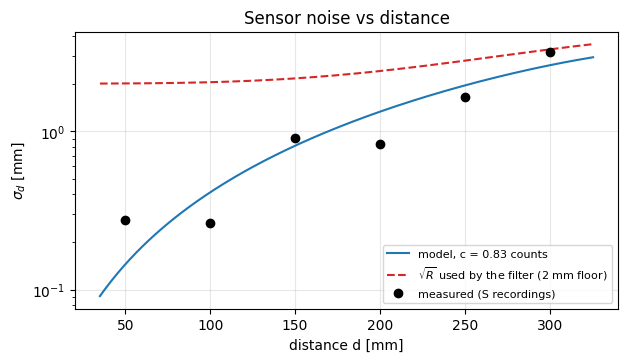

In [4]:
dm_per_count = lambda m: (m - SHARP_B)**2 / SHARP_A                       # library metres per ADC count
NOISE_C = np.exp(np.mean(np.log(stat.m_std / dm_per_count(stat.m))))     # [counts], log fit: every distance counts equally
sigma_d = lambda m: NOISE_C * dd_dm(m) * dm_per_count(m)                  # [m]
SIGMA_CAL = 0.002                                                         # [m] calibration floor
R_of_m = lambda m: sigma_d(m)**2 + SIGMA_CAL**2                           # [m^2]
H = -R_WHEEL                                                              # z = d = H x

m_in = np.linspace(0.06, 0.40, 2000); m_in = m_in[(calibrate(m_in) >= 0.04) & (calibrate(m_in) <= 0.30)]   # 40-300 mm
print(f'c = NOISE_C = {NOISE_C:.2f} counts; sqrt(R) from {1e3*np.sqrt(R_of_m(m_in)).min():.1f} to {1e3*np.sqrt(R_of_m(m_in)).max():.1f} mm over 40-300 mm')
mm = np.linspace(0.06, 0.40, 300)
plt.figure(figsize=(7, 3.6))
plt.semilogy(1e3 * calibrate(mm), 1e3 * sigma_d(mm), label=f'model, c = {NOISE_C:.2f} counts')
plt.semilogy(1e3 * calibrate(mm), 1e3 * np.sqrt(R_of_m(mm)), '--', color='tab:red', label=r'$\sqrt{R}$ used by the filter (2 mm floor)')
plt.semilogy(1e3 * stat.tape, 1e3 * dd_dm(stat.m) * stat.m_std, 'ko', label='measured (S recordings)')
plt.xlabel('distance d [mm]'); plt.ylabel(r'$\sigma_d$ [mm]'); plt.title('Sensor noise vs distance'); plt.legend(fontsize=8); plt.show()

## 4. Process noise $Q(\omega)$

$Q_k = \Delta t^2\big(\sigma_\omega^2 + (k\,\omega_k)^2\big)$: the A2 value standing still (odometry is exact when the wheels do not turn), larger while driving, when the 1D model is wrong if the robot curves or slips. An empirical inflation; $k$ is chosen in section 6.

In [5]:
K_SLIP = 0.05
Q_w = lambda w: DT**2 * (SIGMA_OMEGA**2 + (K_SLIP * w)**2)        # [rad^2] per step, w = mean wheel speed [rad/s]
print(f'Q at 0 / 7 rad/s: {Q_w(0):.2e} / {Q_w(7):.2e} rad^2')

Q at 0 / 7 rad/s: 3.30e-06 / 1.55e-05 rad^2


## 5. Filter and gate

Order as in `robot.cpp`: correction with the new reading, then prediction with the wheel speeds. The gate (`CorrectionUpdate`):

* raw $m$ outside (0.0109, 0.40) m is skipped: drop-outs (24.78 m), NaN/inf, and beyond 30 cm the sensor over-reads;
* calibrated $d$ outside 0.04–0.32 m is skipped (sensor range plus margin);
* $\nu^2 > 9S$ (3σ) is skipped, unless it happens more than 20 times in a row (0.2 s): then $P$ is widened to $P_\text{resync}$ = 9.5 rad² (≈ 10 cm) and the reading is used (the estimate is wrong, not the sensor);
* the counter is reset with the estimator (`ResetGate()`); a skipped reading is logged as $\nu = 0$.

In [6]:
GATE, SIG_RULER = 9.0, 0.005                                               # 3 sigma; ruler uncertainty of the start [m]
M_RAW_MAX, D_MIN, D_MAX, MAX_REJECT = 0.40, 0.04, 0.32, 20
P0_STATE = (SIG_RULER / R_WHEEL)**2                                        # [rad^2]
P_RESYNC = 9.5                                                             # [rad^2] ~ (0.10 m / R_WHEEL)^2
P0 = P0_STATE

def lkf(m, w_mean, Q, x0, P0, gate=None, r_scale=1.0, r_func=None):
    # Same steps as robot.cpp + state_estimator.cpp. m = getFrontDistance() [m], w_mean = (wA + wB)/2 [rad/s]
    # state x = -d/R_WHEEL [rad]; Q is a number or a function of the wheel speed; r_func replaces R(d) if given
    n = len(m); o = {k: np.zeros(n) for k in ['x', 'P', 'xb', 'Pb', 'nu', 'S', 'K', 'z', 'R']}; o['skip'] = np.zeros(n, bool)
    o['rej_range'], o['rej_3s'], o['resync'] = np.zeros(n, bool), np.zeros(n, bool), np.zeros(n, bool)
    x, P, rejected = x0, P0, 0                                 # rejected = 0: ResetGate()
    for k in range(n):
        o['xb'][k], o['Pb'][k] = x, P
        z = calibrate(m[k]); Rk = r_scale * (r_func or R_of_m)(m[k])   # calibrated distance [m] and R(d) [m^2]
        nu = z - H * x; S = H * P * H + Rk
        accept = True
        if gate is not None:                                   # same logic as CorrectionUpdate in the C++
            if not (SHARP_B < m[k] < M_RAW_MAX):
                accept = False                                 # drop-out, NaN/inf (raw value)
            elif not (D_MIN <= z <= D_MAX):
                accept = False; o['rej_range'][k] = True       # outside the sensor range (calibrated)
            elif nu**2 > gate * S:
                rejected += 1
                accept = rejected > MAX_REJECT                 # persistent: the estimate is wrong, re-sync
                if accept:
                    P = P_RESYNC; S = H * P * H + Rk; o['resync'][k] = True
                else:
                    o['rej_3s'][k] = True
            if accept:
                rejected = 0
        if not accept:
            K = 0.0; o['skip'][k] = True
        else:
            K = P * H / S
        x = x + K * nu; P = (1 - K * H) * P
        o['x'][k], o['P'][k], o['nu'][k], o['S'][k], o['K'][k], o['z'][k], o['R'][k] = x, P, nu, S, K, z, Rk
        Qk = Q(w_mean[k]) if callable(Q) else Q
        x = F * x + B * w_mean[k]; P = F * P * F + Qk          # prediction (v = mean wheel speed)
    return o

## 6. Validation on the real drives W1–W7

Seven drives from 300 mm towards the box: W1–W3 at 3.5 V, W4–W5 at 2.5 V, W6–W7 at 5 V. Each is replayed offline, started from the tape distance with $P_0$, with a calibration that does not contain that drive (W1–W3 held out one by one; W4–W7 are not in it). Ground truth is only the tape at the start and the end; during the drive the reference is the odometry rescaled to the tape travel. NIS and rejections are counted while driving.

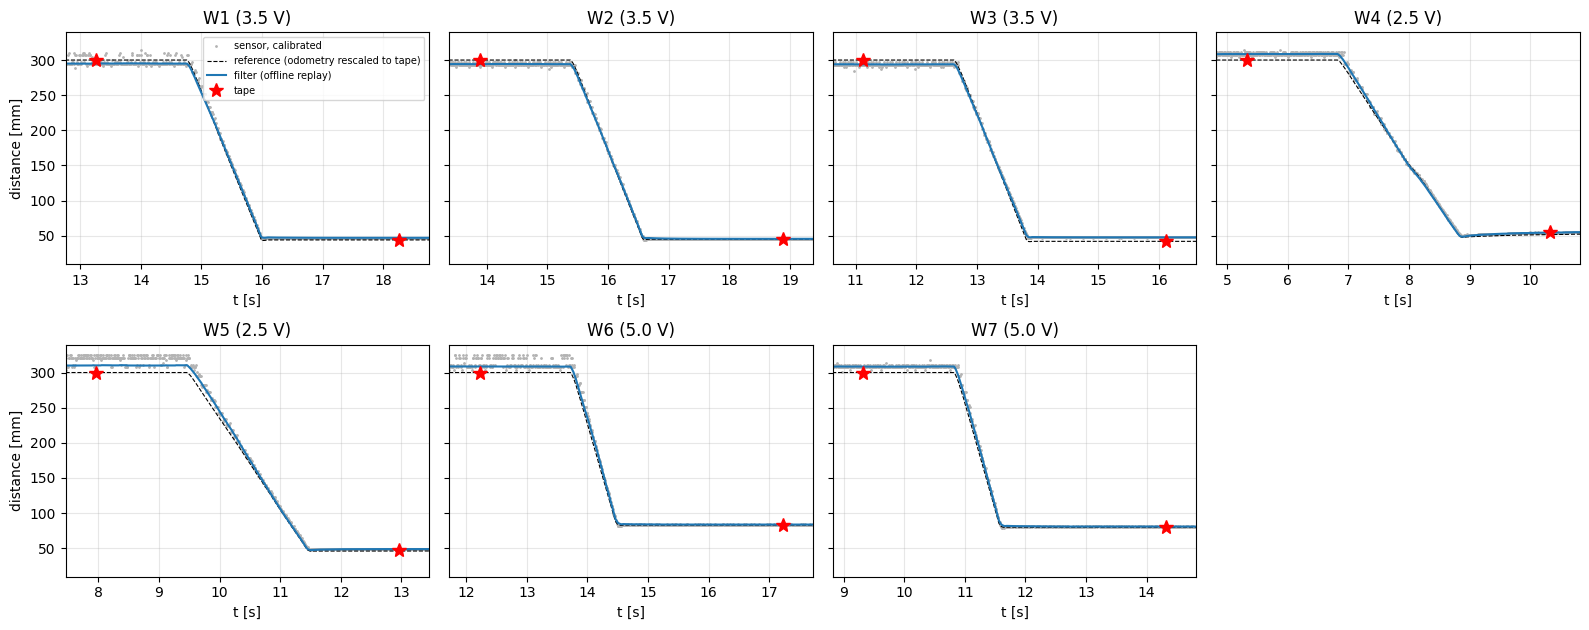

run  V [V]  end error vs tape [mm]  NIS driving (1)  3-sigma rejections (driving)  re-syncs
 W1    3.5                     3.0             1.12                            10         0
 W2    3.5                     0.6             0.94                             0         0
 W3    3.5                     5.6             0.71                             1         0
 W4    2.5                     3.3             0.12                             5         0
 W5    2.5                     2.8             0.45                            31         1
 W6    5.0                     0.6             1.09                            10         0
 W7    5.0                     0.8             1.15                             6         0
end error rms 3.0 mm, mean +2.4 mm


In [7]:
def w_metrics(r, Q, r_func=None):
    o = lkf(r['m'], r['w'], Q, r['d_start'] / -R_WHEEL, P0, gate=GATE, r_func=r_func)
    odo = R_WHEEL * DT * np.concatenate([[0], np.cumsum(r['w'][:-1])])
    ref = r['d_start'] - odo * (r['d_start'] - r['d_end']) / (R_WHEEL * DT * r['w'].sum())   # odometry rescaled to the tape
    acc = ~o['skip'][r['drive']]
    return o, dict(end_err=1e3 * (H * o['x'][-1] - r['d_end']), rms_ref=1e3 * np.sqrt(np.mean((H * o['x'] - ref)**2)),
                   nis_drive=np.mean((o['nu']**2 / o['S'])[r['drive']][acc]), drift=1e3 * np.mean(o['nu'][r['drive']][acc]),
                   rej_3s=int(o['rej_3s'].sum()), rej_3s_drive=int(o['rej_3s'][r['drive']].sum()), resync=int(o['resync'].sum()),
                   rej_range=int(o['rej_range'].sum())), ref

W_VOLT = {'W1': 3.5, 'W2': 3.5, 'W3': 3.5, 'W4': 2.5, 'W5': 2.5, 'W6': 5.0, 'W7': 5.0}
rows = []
fig, ax = plt.subplots(2, 4, figsize=(16, 6.4), sharey=True); ax = ax.ravel(); ax[-1].axis('off')
for a, r in zip(ax, WRUNS):
    use_cal(fit_cal(cal_pts[~cal_pts.source.str.startswith(r['name'][:2])]))       # held out
    o, met, ref = w_metrics(r, Q_w)
    rows.append({'run': r['name'][:2], 'V [V]': W_VOLT[r['name'][:2]], 'end error vs tape [mm]': met['end_err'], 'NIS driving (1)': met['nis_drive'],
                 '3-sigma rejections (driving)': met['rej_3s_drive'], 're-syncs': met['resync']})
    ok = r['m'] < M_RAW_MAX; t0 = r['t'][r['drive']][0]
    a.plot(r['t'][ok], 1e3 * calibrate(r['m'][ok]), '.', ms=2, color='0.7', label='sensor, calibrated')
    a.plot(r['t'], 1e3 * ref, '--', color='k', lw=0.8, label='reference (odometry rescaled to tape)')
    a.plot(r['t'], 1e3 * H * o['x'], 'tab:blue', label='filter (offline replay)')
    a.plot([t0 - 1.5, t0 + 3.5], [1e3 * r['d_start'], 1e3 * r['d_end']], 'r*', ms=10, label='tape')
    a.set(xlim=(t0 - 2, t0 + 4), title=f"{r['name'][:2]} ({W_VOLT[r['name'][:2]]} V)", xlabel='t [s]')
use_cal(CAL_ALL)
ax[0].set_ylabel('distance [mm]'); ax[4].set_ylabel('distance [mm]'); ax[0].legend(fontsize=7)
plt.tight_layout(); plt.show()
vt = pd.DataFrame(rows)
print(vt.round({'end error vs tape [mm]': 1, 'NIS driving (1)': 2}).to_string(index=False))
print(f"end error rms {np.sqrt(np.mean(vt['end error vs tape [mm]']**2)):.1f} mm, mean {vt['end error vs tape [mm]'].mean():+.1f} mm")

In [8]:
# Odometry vs tape per drive, heading change from the gyro, and the part explained by driving an arc instead of a line
from mr_common import WHEELBASE
rows = []
for r in WRUNS:
    df = load_log(DATA_A3 / (r['name'] + '.csv'), firmware='identification_a3'); st = window(df, 0.5, 5.0)
    mv = np.flatnonzero(np.abs(r['w']) > 0); odo = R_WHEEL * DT * r['w'].sum(); tape = r['d_start'] - r['d_end']
    th = np.sum((df.gz - st.gz.mean()).values[mv[0]:mv[-1] + 100]) * DT          # heading change [rad]
    chord = odo * np.sin(th) / th                                                 # forward travel on an arc of constant curvature
    rows.append({'run': r['name'][:2], 'V [V]': W_VOLT[r['name'][:2]], 'w [rad/s]': np.median(r['w'][np.abs(r['w']) > 0.8 * np.abs(r['w']).max()]),
                 'odometry - tape [%]': 100 * (odo - tape) / tape, 'heading [deg]': np.degrees(th),
                 'arc - chord [mm]': 1e3 * (odo - chord), 'remaining [mm]': 1e3 * (chord - tape)})
print(pd.DataFrame(rows).round(1).to_string(index=False))

q_k = lambda kk: (lambda w: DT**2 * (SIGMA_OMEGA**2 + (kk * w)**2))
out = []
for name, q in {'A2 Q (constant)': Q, 'Q(w), k = 0.05 (chosen)': Q_w, 'Q(w), k = 0.10': q_k(0.10)}.items():
    per = {}
    for r in WRUNS:
        use_cal(fit_cal(cal_pts[~cal_pts.source.str.startswith(r['name'][:2])]))
        m = w_metrics(r, q)[1]; per.setdefault(W_VOLT[r['name'][:2]], []).append((m['nis_drive'], m['rej_3s_drive']))
    out.append({'Q': name, **{f'{v} V: NIS / rej.': f"{np.mean([x[0] for x in l]):.2f} / {sum(x[1] for x in l)}" for v, l in sorted(per.items())}})
use_cal(CAL_ALL)
print(); print(pd.DataFrame(out).to_string(index=False))

# R on W1-W3 (final calibration, as when it was chosen)
R_MID = R_of_m(np.interp(0.175, calibrate(np.linspace(0.06, 0.40, 2000)), np.linspace(0.06, 0.40, 2000)))
out = []
for name, rf in {f'constant R = ({1e3*np.sqrt(R_MID):.1f} mm)^2': (lambda m: R_MID), 'R(d), sigma_cal 2 mm (chosen)': None,
                 'R(d), sigma_cal 1 mm': (lambda m: sigma_d(m)**2 + 0.001**2)}.items():
    ms = [w_metrics(r, Q_w, r_func=rf)[1] for r in WRUNS[:3]]
    out.append({'R (W1-W3)': name, 'NIS driving (1)': round(np.mean([m['nis_drive'] for m in ms]), 2), '3-sigma rejections': sum(m['rej_3s_drive'] for m in ms)})
print(); print(pd.DataFrame(out).to_string(index=False))

run  V [V]  w [rad/s]  odometry - tape [%]  heading [deg]  arc - chord [mm]  remaining [mm]
 W1    3.5        6.6                 -0.6           -2.1               0.1            -1.6
 W2    3.5        6.6                 -2.3           -2.2               0.1            -6.0
 W3    3.5        6.5                 -3.6            3.0               0.1            -9.4
 W4    2.5        4.2                  6.0           22.0               6.3             8.3
 W5    2.5        4.2                  7.2           18.4               4.6            13.4
 W6    5.0        9.6                  5.3            8.6               0.9            10.7
 W7    5.0        9.7                  4.0            7.3               0.6             8.1

                      Q 2.5 V: NIS / rej. 3.5 V: NIS / rej. 5.0 V: NIS / rej.
        A2 Q (constant)         0.32 / 36         1.07 / 22         1.34 / 23
Q(w), k = 0.05 (chosen)         0.28 / 36         0.92 / 11         1.12 / 16
         Q(w), k = 0.10      


                    R (W1-W3)  NIS driving (1)  3-sigma rejections
      constant R = (2.3 mm)^2             0.97                  23
R(d), sigma_cal 2 mm (chosen)             0.93                   9
         R(d), sigma_cal 1 mm             1.45                  30


* **Odometry vs speed:** not monotonic (+6…7 % at 4.2 rad/s, −1…−4 % at 6.6, +4…5 % at 9.7). Driving an arc explains ≤ 6 mm; the rest splits by session (W1–W3 −2…−9 mm, W4–W7 +8…+13 mm), not by speed: no speed-proportional slip.
* **Q:** $k$ = 0.05 gives NIS 0.92 (3.5 V) and 1.12 (5 V) with fewer rejections than the A2 $Q$; at 2.5 V every $Q$ gives NIS ≪ 1 (slow: the floor of $R$ dominates; most rejections are W5's start, sensor +20 mm). $k$ = 0.05 is kept. (It dropped from 0.10 after the calibration refit: part of the earlier mismatch was calibration error.)
* **R:** $R(d)$ with the 2 mm floor gives the fewest rejections; a constant $R$ trusts the sensor too much far away, a 1 mm floor is over-confident.

## 7. Consistency with the firmware
The firmware (`INTERNAL-StateEstimation_StateFeedback/`) is the reference. This cell reads its constants from `state_estimator.h/.cpp` and checks that they equal the values used here.

In [9]:
FW = Path('INTERNAL-StateEstimation_StateFeedback')
fw_src = (FW / 'state_estimator.h').read_text() + (FW / 'state_estimator.cpp').read_text()

def fw_value(name):
    # numeric value of 'NAME = <number>' in the firmware source
    m = re.search(rf'\b{name}\s*=\s*([-+0-9.eE]+)f?\s*;', fw_src)
    assert m, f'{name} not found in the firmware'
    return float(m.group(1))

nb_values = {'SIGMA_OMEGA': SIGMA_OMEGA, 'K_SLIP': K_SLIP, 'P0_STATE': P0_STATE, 'P_RESYNC': P_RESYNC,
             'CAL_C2': CAL_C2, 'CAL_C1': CAL_C1, 'CAL_C0': CAL_C0, 'SHARP_A': SHARP_A, 'SHARP_B': SHARP_B, 'NOISE_C': NOISE_C, 'SIGMA_CAL': SIGMA_CAL,
             'M_RAW_MAX': M_RAW_MAX, 'D_MIN': D_MIN, 'D_MAX': D_MAX, 'GATE': GATE, 'MAX_REJECT': MAX_REJECT}
check = pd.DataFrame({'firmware': {k: fw_value(k) for k in nb_values}, 'notebook': nb_values})
check['equal'] = np.isclose(check.firmware, check.notebook, rtol=1e-6, atol=0)
print(check.to_string(float_format=lambda v: f'{v:.7g}'))
assert re.search(r'H\s*=\s*\{\s*-R_WHEEL\s*\}', fw_src) and H == -R_WHEEL, 'H must be -R_WHEEL in both'
assert check['equal'].all(), 'notebook and firmware differ: update one of them (same commit)'
print('H = -R_WHEEL in both. Notebook and firmware match.')

               firmware    notebook  equal
SIGMA_OMEGA   0.1816457   0.1816457   True
K_SLIP             0.05        0.05   True
P0_STATE     0.02366864  0.02366864   True
P_RESYNC            9.5         9.5   True
CAL_C2       -0.8111222  -0.8111222   True
CAL_C1         1.227741    1.227741   True
CAL_C0      -0.03570785 -0.03570785   True
SHARP_A         24.7694     24.7694   True
SHARP_B       0.0109311   0.0109311   True
NOISE_C       0.8296784   0.8296784   True
SIGMA_CAL         0.002       0.002   True
M_RAW_MAX           0.4         0.4   True
D_MIN              0.04        0.04   True
D_MAX              0.32        0.32   True
GATE                  9           9   True
MAX_REJECT           20          20   True
H = -R_WHEEL in both. Notebook and firmware match.


## 8. Closed loop on the robot (C1–C6)

Button 1 (estimator), button 0 (controller); ValueOut1 = tape start, ValueOut0 = target [m]. C4: hand in front of the sensor (19.5 s, 30.8 s); C5: robot pushed (34–38 s) and pulled (48–49.5 s). C1–C5 were recorded with $K = +2$ and the flipped formula $K(x_\text{ref} - \hat x)$, identical to the template's $K(\hat x - x_\text{ref})$ with $K = -2$; C6 with the final graded firmware (template formula, $K = -2$). In C6 the real start gap was ≈ 265 mm, not the 250 mm typed: the gate rejected the sensor for 0.2 s, then re-synced. **Set-up:** standing still in this box/floor-tape set-up (`S_C150mm`) the calibrated sensor reads +8.9 mm vs the tape (+10.9 mm vs a ruler); `S_150mm` gave +0.5 mm.

**Choice of $K$.** With $\omega = K(\hat x - x_\text{ref})$ and $\dot x = \omega$ (velocity loop much faster), $x_{k+1} - x_\text{ref} = (1 + \Delta t\,K)(x_k - x_\text{ref})$: for $K = -2$ the pole is 0.98, $\tau$ ≈ 0.5 s, and a 100 mm step settles within 5 mm after $\ln(20)\,\tau$ ≈ 1.5 s (measured 1.0–1.7 s). A larger $|K|$ is faster but gives larger voltage peaks and wheel slip at the start (C2: 7.4 V).

K = -2.0: pole 0.98, tau 0.49 s, predicted settling 100 mm -> 5 mm: 1.5 s
S_C150mm (C set-up, robot still): calibrated 158.9 mm, tape 150 mm, ruler 148 mm
run  target [mm]  settling 5 mm [s]  overshoot [mm]  est - tape [mm]  cal. sensor - tape [mm]  rejected readings
 C1        150.0                1.4             1.3              7.0                      7.3                  1
C1b        150.0                1.4             0.0                –                        –                  1
 C2        100.0                1.7             0.6              5.1                      5.0                  5
 C3        200.0                1.0             1.5              9.9                     12.2                  3
 C4        150.0                1.5             0.5             10.0                     10.3                 93
 C5        150.0                1.4             3.0              8.0                      8.3                187
 C6        150.0                1.4             1.0   

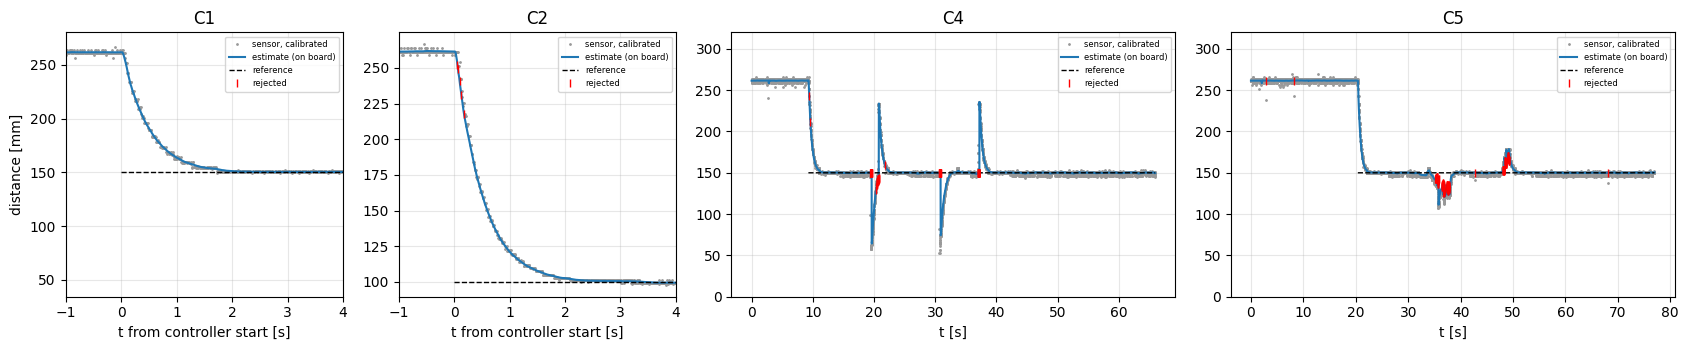

C2 fast part, A2 Q (constant): NIS 2.07, rejections 7
C2 fast part, k = 0.05: NIS 1.57, rejections 5
C2 fast part, k = 0.15: NIS 1.18, rejections 2


In [10]:
K_CTRL = -2.0
pole = 1 + DT * K_CTRL; tau_c = -DT / np.log(pole)
print(f'K = {K_CTRL}: pole {pole:.2f}, tau {tau_c:.2f} s, predicted settling 100 mm -> 5 mm: {np.log(20)*tau_c:.1f} s')

m_c = load_log(DATA_A3 / 'S_C150mm.csv', firmware='identification_a3').front.values
print(f'S_C150mm (C set-up, robot still): calibrated {1e3*calibrate(m_c).mean():.1f} mm, tape 150 mm, ruler 148 mm')

C_TAPE_END = {'C1': 0.143, 'C1b': None, 'C2': 0.095, 'C3': 0.190, 'C4': 0.140, 'C5': 0.142, 'C6': 0.140}   # [m] LOGBOOK
C_DISTURB = {'C4': 19.5, 'C5': 34.0}                                                            # [s] first disturbance
CRUNS, rows = {}, []
for f in sorted(DATA_A3.glob('C*_start*_target*.csv')):
    name = f.stem.split('_')[0]; df = load_log(f, firmware='state_feedback'); t = df.t.values
    on = np.flatnonzero((df.uA.abs() + df.uB.abs()).values > 0)              # controller active
    c = CRUNS[name] = dict(df=df, t=t, est=H * df.xhat_post.values, ref=H * df.xref.values, zc=calibrate(df.front.values),
                           t_on=t[on[0]], t_off=t[on[-1]], rej=(df.nu.values == 0))
    target = np.median(c['ref'][on]); err = c['est'] - target
    first = (t >= c['t_on']) & (t < min(c['t_off'], C_DISTURB.get(name, np.inf) - 0.5))   # first approach and hold
    out = np.flatnonzero(first & (np.abs(err) > 0.005))
    d0 = c['est'][on[0]]; end = (t > c['t_off'] - 3) & (t <= c['t_off']); tape = C_TAPE_END[name]
    rows.append({'run': name, 'target [mm]': 1e3 * target, 'settling 5 mm [s]': t[out[-1]] - c['t_on'] if len(out) else 0.0,
                 'overshoot [mm]': 1e3 * max(0.0, np.max(np.sign(target - d0) * (c['est'][first] - target))),
                 'est - tape [mm]': 1e3 * (c['est'][end].mean() - tape) if tape else np.nan,
                 'cal. sensor - tape [mm]': 1e3 * (np.median(c['zc'][end]) - tape) if tape else np.nan,
                 'rejected readings': int(c['rej'][on[0]:on[-1]].sum())})
print(pd.DataFrame(rows).round(1).to_string(index=False, na_rep='–'))

fig, ax = plt.subplots(1, 4, figsize=(17, 3.6), gridspec_kw={'width_ratios': [1, 1, 1.6, 1.6]})
for a, name in zip(ax, ['C1', 'C2', 'C4', 'C5']):
    c = CRUNS[name]; ok = c['df'].front.values < M_RAW_MAX; t = c['t'] if name in C_DISTURB else c['t'] - c['t_on']
    a.plot(t[ok], 1e3 * c['zc'][ok], '.', ms=2, color='0.6', label='sensor, calibrated')
    ctrl = c['t'] >= c['t_on']                                             # reference only while the controller runs
    a.plot(t, 1e3 * c['est'], label='estimate (on board)'); a.plot(t[ctrl], 1e3 * c['ref'][ctrl], 'k--', lw=1, label='reference')
    a.plot(t[c['rej']], 1e3 * c['est'][c['rej']], 'r|', ms=6, label='rejected')
    if name not in C_DISTURB:
        a.set(xlim=(-1, 4), xlabel='t from controller start [s]')
    else:
        a.set(xlabel='t [s]', ylim=(0, 320))
    a.set(title=name); a.legend(fontsize=6)
ax[0].set_ylabel('distance [mm]'); plt.tight_layout(); plt.show()

# K_slip at higher speed: fast part of C2 (|w| > 3 rad/s, up to 10 rad/s, hard start with slip), replayed from the log
c = CRUNS['C2']; df = c['df']; w = ((df.wA + df.wB) / 2).values; fast = (np.abs(w) > 3)[1:]
for lab, q in [('A2 Q (constant)', Q), ('k = 0.05', q_k(0.05)), ('k = 0.15', q_k(0.15))]:
    o = lkf(df.front.values[1:], w[1:], q, df.xhat_prior.values[0], df.P_post.values[0] + Q, gate=GATE)
    acc = ~o['skip'] & fast
    print(f"C2 fast part, {lab}: NIS {np.mean((o['nu']**2 / o['S'])[acc]):.2f}, rejections {int((o['rej_3s'] & fast).sum())}")

## 9. Conclusions and limitations

* **Closed loop works:** settling within 5 mm in 1.0–1.7 s, overshoot ≤ 1.5 mm (3 mm after the push), estimate held on the target within 0.1 mm, also backwards (C3).
* **The end error is the sensor, not the filter:** drives end +0.6 … +5.6 mm from the tape (rms 3.0 mm over 7), closed-loop runs 5–10 mm, while the estimate follows the calibrated sensor within 0.1 mm. The offset is systematic and depends on the set-up (+9…11 mm in the C set-up), which $Q$ and $R$, models of random errors, cannot remove. Subtracting the offset seen at the tape start lowers the closed-loop end errors (rms 8.2 → 4.6 mm) but over-corrects (extensions).
* **Calibration and $R(d)$:** needed because the library curve over-reads; $R$ grows ≈ $d^2$ (ADC counts), with a 2 mm floor that treats a systematic error as white noise. Valid 42–300 mm.
* **Gate:** drop-outs and out-of-range readings are skipped; a hand (C4) is rejected for 0.2 s, then the filter re-syncs; when the robot is pushed (C5) the estimate keeps following the sensor.
* **$Q(\omega)$:** tested at 2.5, 3.5 and 5 V; $k$ = 0.05 is consistent at 3.5 and 5 V. It is an empirical inflation while driving, not a slip model: the odometry error is not proportional to speed. C2's hard start (NIS 1.57) points at acceleration: W6–W7 reach the same speed with NIS 1.12.
* **Limitations:** 5 mm ruler uncertainty assumed; slip and curving modelled as white noise, while on one run they act like a scale error; the reference during the drives is rescaled odometry.